# Retraining KRL Disruption Classification

Tujuan:
1. Mengklasifikasikan teks sebagai disruption atau not_disruption.
2. Mengklasifikasikan severity untuk disruption:
   light, moderate, severe.

Tahap awal:
- Audit struktur dan kualitas data.
- EDA distribusi label dan duplikasi.
- Menentukan preprocessing dan strategi pembagian data.

In [71]:
from pathlib import Path
import pandas as pd
import unicodedata
import matplotlib.pyplot as plt
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.model_selection import StratifiedGroupKFold
from collections import defaultdict

In [ ]:
Source = Path(
    "/Users/naufal/Moobby_back/evaluation/krl_tweets_clean.csv"
)

In [ ]:
df_raw = pd.read_csv(
    Source,
    dtype=str,
    keep_default_na=False,
    encoding="utf-8-sig",
)

df = df_raw.copy(deep=True)

print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))
print("Kolom:", df.columns.tolist())

Jumlah baris: 1618
Jumlah kolom: 8
Kolom: ['tweet_id', 'date', 'account', 'source_url', 'full_text', 'disruption_label', 'severity', 'found_via']


## Audit Data

Memeriksa nilai kosong, label yang tidak valid, dan kesesuaian severity.

Severity kosong diperbolehkan untuk not_disruption.
Disruption wajib memiliki severity light, moderate, atau severe.

In [ ]:
blank_counts = df.apply(
    lambda column: column.str.strip().eq("").sum()
)
display(
    blank_counts
    .rename("jumlah_kosong")
    .to_frame()
)

,jumlah_kosong
tweet_id,0
date,0
account,0
source_url,0
full_text,0
disruption_label,0
severity,892
found_via,0


In [ ]:
display(
    pd.crosstab(
        df["disruption_label"],
        df["severity"].replace("", "(kosong)"),
    )
)

severity,(kosong),light,moderate,severe
disruption_label,,,,
disruption,0,448,205,73
not_disruption,892,0,0,0


## Audit Duplikasi

Memeriksa duplikasi ID, URL, dan teks, serta konflik label
pada teks yang identik. Belum ada baris yang dihapus.

In [ ]:
text_counts = df["full_text"].value_counts()

label_variations = (
    df.groupby("full_text", sort=False)[
        ["disruption_label", "severity"]
    ]
    .nunique()
)

conflicting_groups = label_variations.gt(1).any(axis=1)

In [ ]:
duplicate_audit = pd.Series({
    "duplikat_id_tambahan": df["tweet_id"].duplicated().sum(),
    "duplikat_url_tambahan": df["source_url"].duplicated().sum(),
    "duplikat_teks_tambahan": df["full_text"].duplicated().sum(),
    "kelompok_teks_berulang": text_counts.gt(1).sum(),
    "jumlah_teks_unik": df["full_text"].nunique(),
    "kelompok_teks_label_berkonflik": conflicting_groups.sum(),
})

display(duplicate_audit.to_frame("jumlah"))

,jumlah
duplikat_id_tambahan,0
duplikat_url_tambahan,0
duplikat_teks_tambahan,301
kelompok_teks_berulang,91
jumlah_teks_unik,1317
kelompok_teks_label_berkonflik,0


In [ ]:
def normalize_text(text):
    return " ".join(
        unicodedata.normalize("NFKC", text)
        .casefold()
        .split()
    )

df["model_text"] = df["full_text"].map(normalize_text)

In [ ]:
normalized_label_variations = (
    df.groupby("model_text", sort=False)[
        ["disruption_label", "severity"]
    ]
    .nunique()
)

normalized_conflicts = (
    normalized_label_variations.gt(1).any(axis=1)
)

normalization_audit = pd.Series({
    "teks_kosong_setelah_normalisasi": (
        df["model_text"].eq("").sum()
    ),
    "teks_berubah_setelah_normalisasi": (
        df["full_text"].ne(df["model_text"]).sum()
    ),
    "teks_unik_sebelum_normalisasi": df["full_text"].nunique(),
    "teks_unik_setelah_normalisasi": df["model_text"].nunique(),
    "kelompok_label_berkonflik_setelah_normalisasi": (
        normalized_conflicts.sum()
    ),
})

display(normalization_audit.to_frame("jumlah"))

,jumlah
teks_kosong_setelah_normalisasi,0
teks_berubah_setelah_normalisasi,1611
teks_unik_sebelum_normalisasi,1317
teks_unik_setelah_normalisasi,1311
kelompok_label_berkonflik_setelah_normalisasi,0


In [ ]:
df_model = (
    df.drop_duplicates(subset="model_text", keep="first")
    .copy()
    .reset_index(drop=True)
)

print("Baris sebelum deduplikasi:", len(df))
print("Baris dataset modeling:", len(df_model))
print("Salinan tambahan dikeluarkan:", len(df) - len(df_model))

Baris sebelum deduplikasi: 1618
Baris dataset modeling: 1311
Salinan tambahan dikeluarkan: 307


In [ ]:
relevance_summary = (
    df_model["disruption_label"]
    .value_counts()
    .rename_axis("label")
    .to_frame("jumlah")
)

relevance_summary["persentase"] = (
    relevance_summary["jumlah"] / len(df_model) * 100
).round(2)

display(relevance_summary)

,jumlah,persentase
label,,
not_disruption,752,57.36
disruption,559,42.64


In [ ]:
severity_summary = (
    df_model.loc[
        df_model["disruption_label"].eq("disruption"),
        "severity",
    ]
    .value_counts()
    .reindex(["light", "moderate", "severe"], fill_value=0)
    .rename_axis("severity")
    .to_frame("jumlah")
)

severity_summary["persentase"] = (
    severity_summary["jumlah"] / severity_summary["jumlah"].sum() * 100
).round(2)

display(severity_summary)

,jumlah,persentase
severity,,
light,342,61.18
moderate,151,27.01
severe,66,11.81


In [ ]:
df_model["character_count"] = df_model["model_text"].str.len()

df_model["word_count"] = (
    df_model["model_text"]
    .str.split()
    .str.len()
)

In [ ]:
display(
    df_model.groupby("disruption_label")[
        ["character_count", "word_count"]
    ]
    .agg(["count", "min", "median", "mean", "max"])
    .round(2)
)

character_count                         word_count      \
                           count min median    mean  max      count min   
disruption_label                                                          
disruption                   559  15  223.0  225.73  675        559   3   
not_disruption               752   8  167.0  168.81  603        752   1   

                                    
                 median   mean max  
disruption_label                    
disruption         32.0  32.21  91  
not_disruption     26.0  25.53  79

In [ ]:
display(
    df_model.loc[
        df_model["disruption_label"].eq("disruption")
    ]
    .groupby("severity")[
        ["character_count", "word_count"]
    ]
    .agg(["count", "min", "median", "mean", "max"])
    .reindex(["light", "moderate", "severe"])
    .round(2)
)

character_count                         word_count                    \
                   count min median    mean  max      count min median   mean   
severity                                                                        
light                342  15  150.0  175.75  592        342   3   23.5  26.26   
moderate             151  81  319.0  334.18  675        151  10   43.0  44.20   
severe                66  57  236.5  236.61  524         66  10   36.0  35.58   

              
         max  
severity      
light     79  
moderate  91  
severe    72

In [ ]:
severity_rows = df_model.loc[
    df_model["disruption_label"].eq("disruption")
]

shortest_samples = (
    severity_rows
    .sort_values(["word_count", "character_count", "tweet_id"])
    .groupby("severity", sort=False)
    .head(2)
    .assign(review_group="terpendek")
)

longest_samples = (
    severity_rows
    .sort_values(
        ["word_count", "character_count", "tweet_id"],
        ascending=[False, False, True],
    )
    .groupby("severity", sort=False)
    .head(2)
    .assign(review_group="terpanjang")
)

review_samples = pd.concat(
    [shortest_samples, longest_samples],
    ignore_index=True,
)

In [ ]:
with pd.option_context("display.max_colwidth", None):
    display(
        review_samples[[
            "review_group",
            "tweet_id",
            "severity",
            "character_count",
            "word_count",
            "full_text",
        ]]
    )

,review_group,tweet_id,severity,character_count,word_count,full_text
0,terpendek,2120314161871941644,light,15,3,krl ngapo delay
1,terpendek,2038567674280919333,light,18,4,girl krl nya delay
2,terpendek,2093236950576878018,severe,57,10,KRL Greenline Back to Normal After Being Delayed by Crowd
3,terpendek,2051258377309933638,moderate,82,10,"KRL Alami Gangguan Listrik, Perjalanan Tertahan di Lintas Jurangmangu-Pondok Ranji"
4,terpendek,930088938844377088,moderate,81,12,"sehingga perjalanan KRL menjadi terlambat dan ada beberapa KA dibatalkan, tks. |2"
5,terpendek,2048790724913840178,severe,93,15,"Apakah gara2 ini jadi KRL di bekasi timur tertahan, dan mengakibatkan KA jarak jauh menabrak?"
6,terpanjang,2031739579980517680,moderate,671,91,"Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Bogor (PP) saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Untuk informasi terbaru mengenai perjalanan Commuter Line silakan Kakak dapat cek secara berkala timeline media sosial kami serta aplikasi C-Access ya Kak. Tks.🙏"
7,terpanjang,2031738402018906198,moderate,666,90,"Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Nambo saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Untuk informasi terbaru mengenai perjalanan Commuter Line silakan Kakak dapat cek secara berkala timeline media sosial kami serta aplikasi C-Access ya Kak. Tks.🙏"
8,terpanjang,2031752269251981500,light,574,79,Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Sebelumnya adanya gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Bogor (PP) saat ini telah selesai ditangani oleh petugas. Perjalanan Commuter Line di lokasi sudah dapat dilalui dan proses penguraian kepadatan dilintas. Untuk informasi terbaru mengenai perjalanan Commuter Line silakan Kakak dapat cek secara berkala timeline media sosial kami serta aplikasi C-Access ya Kak. Tks.🙏
9,terpanjang,2031754740179288559,light,574,79,Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Sebelumnya adanya gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Bogor–Jakarta Kota (PP) saat ini telah selesai ditangani oleh petugas. Perjalanan Commuter Line di lokasi sudah dapat dilalui dan proses penguraian kepadatan dilintas. Untuk informasi terbaru mengenai perjalanan Commuter Line silakan Kakak dapat cek secara berkala timeline media sosial kami serta aplikasi C-Access ya Kak. Tks.🙏


In [ ]:
df_model["parsed_date"] = pd.to_datetime(
    df_model["date"],
    errors="coerce",
    utc=True,
)

date_summary = pd.Series({
    "tanggal_gagal_diparsing": df_model["parsed_date"].isna().sum(),
    "tanggal_terawal": df_model["parsed_date"].min(),
    "tanggal_terakhir": df_model["parsed_date"].max(),
})

display(date_summary.to_frame("hasil"))

,hasil
tanggal_gagal_diparsing,878
tanggal_terawal,2014-01-21 00:00:00+00:00
tanggal_terakhir,2026-11-14 00:00:00+00:00


In [ ]:
year_distribution = pd.crosstab(
    df_model["parsed_date"].dt.year,
    df_model["disruption_label"],
)

display(year_distribution)

disruption_label,disruption,not_disruption
parsed_date,,
2014.0,6,0
2015.0,15,0
2016.0,5,0
2017.0,15,0
2018.0,1,0
2019.0,3,64
2020.0,15,77
2021.0,4,39
2022.0,2,21


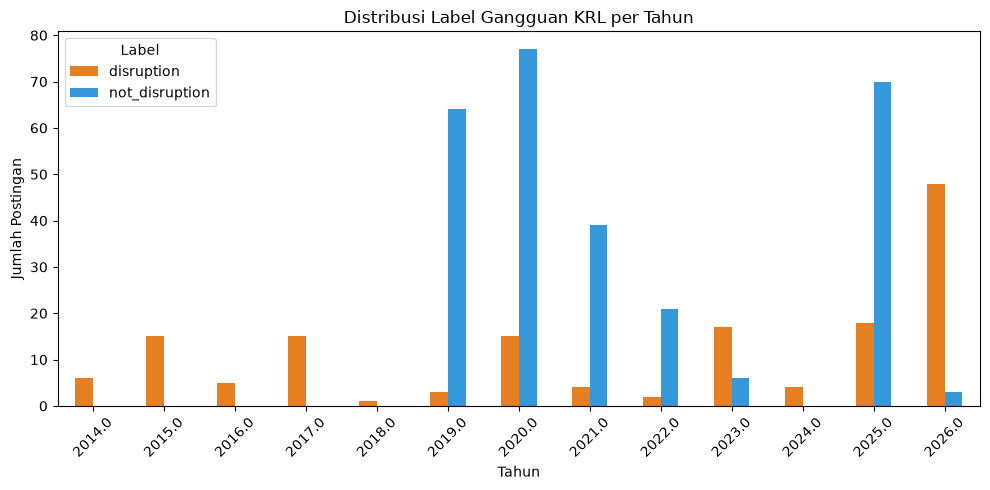

In [30]:
ax = year_distribution.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#E67E22", "#3498DB"],
)

ax.set_title("Distribusi Label Gangguan KRL per Tahun")
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah Postingan")
ax.legend(title="Label")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [31]:
print("Tanggal gagal diparsing:", df_model["parsed_date"].isna().sum())
print("Tanggal terawal:", df_model["parsed_date"].min())
print("Tanggal terakhir:", df_model["parsed_date"].max())

Tanggal gagal diparsing: 878
Tanggal terawal: 2014-01-21 00:00:00+00:00
Tanggal terakhir: 2026-11-14 00:00:00+00:00


In [32]:
date_text = df_model["date"].str.strip()

has_full_date = date_text.str.fullmatch(
    r"[A-Za-z]{3} \d{1,2}, \d{4}",
    na=False,
)

df_model["parsed_date"] = pd.to_datetime(
    date_text.where(has_full_date),
    format="%b %d, %Y",
    errors="coerce",
)

In [33]:
date_audit = pd.Series({
    "jumlah_baris": len(df_model),

    "tanggal_lengkap_berhasil_diparsing": (
        df_model["parsed_date"].notna().sum()
    ),

    "tanggal_lengkap_gagal_diparsing": (
        has_full_date & df_model["parsed_date"].isna()
    ).sum(),

    "tanpa_tanggal_lengkap": (~has_full_date).sum(),
})

display(date_audit.to_frame("jumlah"))

,jumlah
jumlah_baris,1311
tanggal_lengkap_berhasil_diparsing,433
tanggal_lengkap_gagal_diparsing,0
tanpa_tanggal_lengkap,878


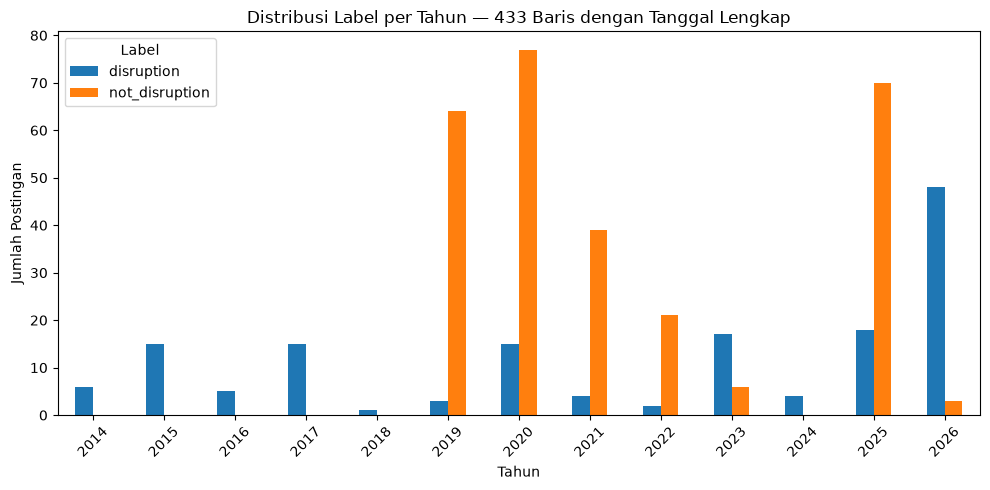

In [34]:
dated_rows = df_model.loc[
    df_model["parsed_date"].notna()
].copy()

year_distribution = pd.crosstab(
    dated_rows["parsed_date"].dt.year,
    dated_rows["disruption_label"],
)

ax = year_distribution.plot(
    kind="bar",
    figsize=(10, 5),
)

ax.set_title(
    f"Distribusi Label per Tahun — "
    f"{len(dated_rows)} Baris dengan Tanggal Lengkap"
)
ax.set_xlabel("Tahun")
ax.set_ylabel("Jumlah Postingan")
ax.legend(title="Label")
ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [35]:
collection_distribution = pd.crosstab(
    df_model["found_via"],
    df_model["disruption_label"],
).reindex(
    columns=["disruption", "not_disruption"],
    fill_value=0,
)

collection_distribution = collection_distribution.loc[
    collection_distribution.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

print("Jumlah kategori found_via:", len(collection_distribution))

Jumlah kategori found_via: 27


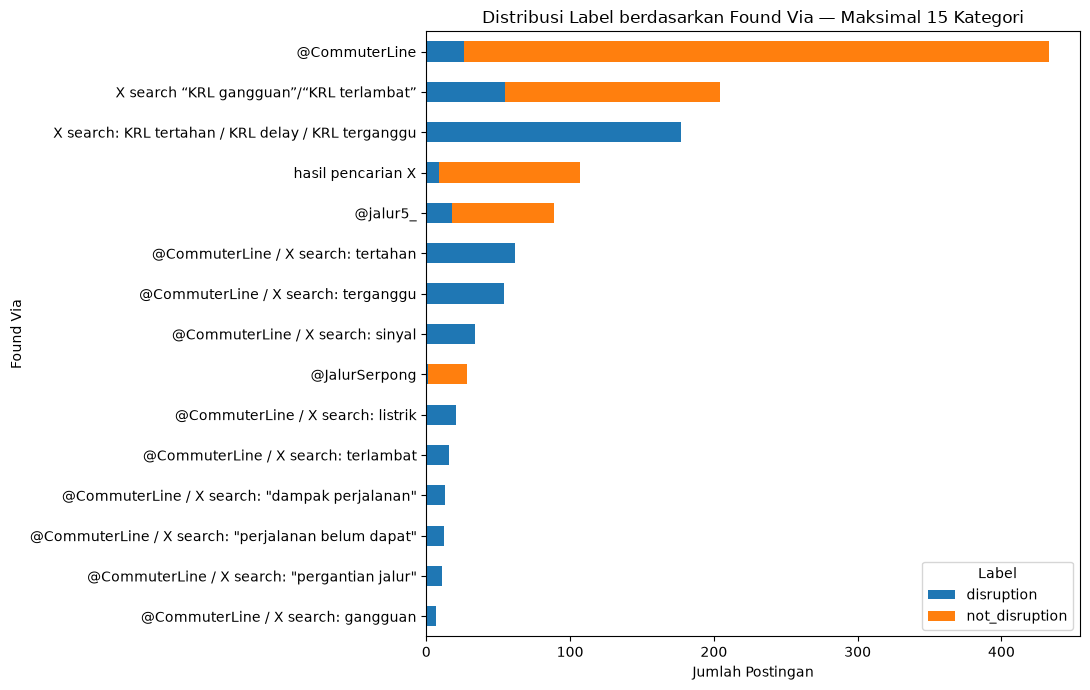

In [36]:
ax = collection_distribution.head(15).plot(
    kind="barh",
    stacked=True,
    figsize=(11, 7),
)

ax.set_title("Distribusi Label berdasarkan Found Via — Maksimal 15 Kategori")
ax.set_xlabel("Jumlah Postingan")
ax.set_ylabel("Found Via")
ax.legend(title="Label")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [37]:
account_distribution = pd.crosstab(
    df_model["account"],
    df_model["disruption_label"],
).reindex(
    columns=["disruption", "not_disruption"],
    fill_value=0,
)

account_distribution = account_distribution.loc[
    account_distribution.sum(axis=1)
    .sort_values(ascending=False)
    .index
]

print("Jumlah akun unik:", len(account_distribution))

Jumlah akun unik: 347


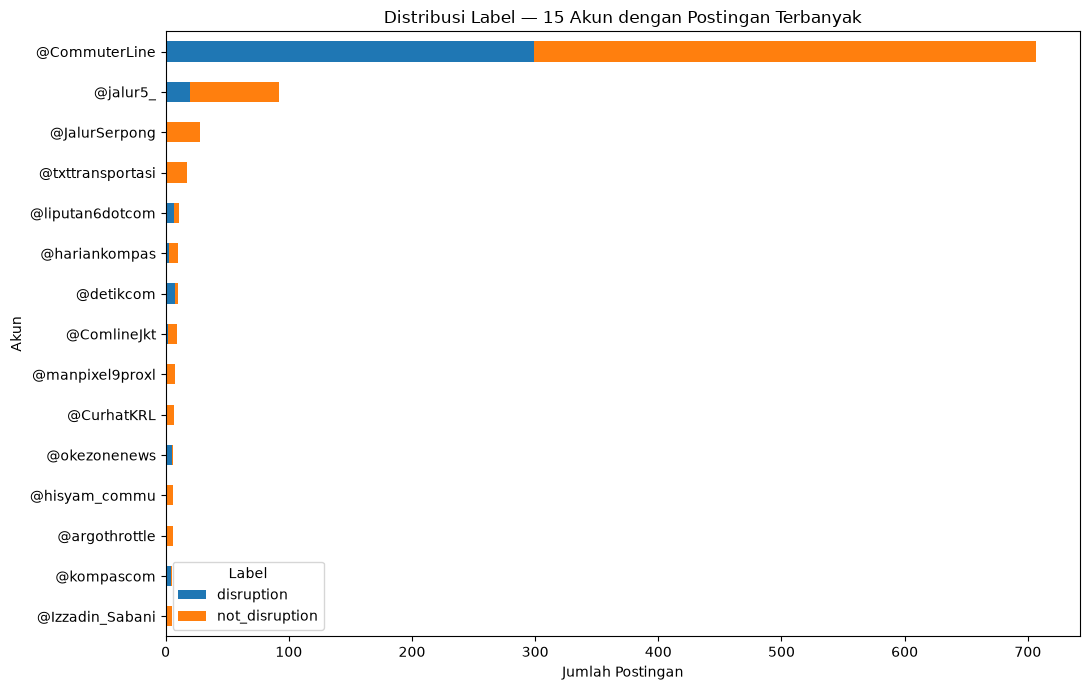

In [38]:
ax = account_distribution.head(15).plot(
    kind="barh",
    stacked=True,
    figsize=(11, 7),
)

ax.set_title("Distribusi Label — 15 Akun dengan Postingan Terbanyak")
ax.set_xlabel("Jumlah Postingan")
ax.set_ylabel("Akun")
ax.legend(title="Label")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [39]:
account_counts = df_model["account"].value_counts()

largest_account = account_counts.index[0]
largest_count = account_counts.iloc[0]
largest_percentage = largest_count / len(df_model) * 100

print("Jumlah akun unik:", len(account_counts))
print("Akun dengan data terbanyak:", largest_account)
print("Jumlah postingan:", largest_count)
print(f"Kontribusi terhadap dataset: {largest_percentage:.2f}%")

Jumlah akun unik: 347
Akun dengan data terbanyak: @CommuterLine
Jumlah postingan: 707
Kontribusi terhadap dataset: 53.93%


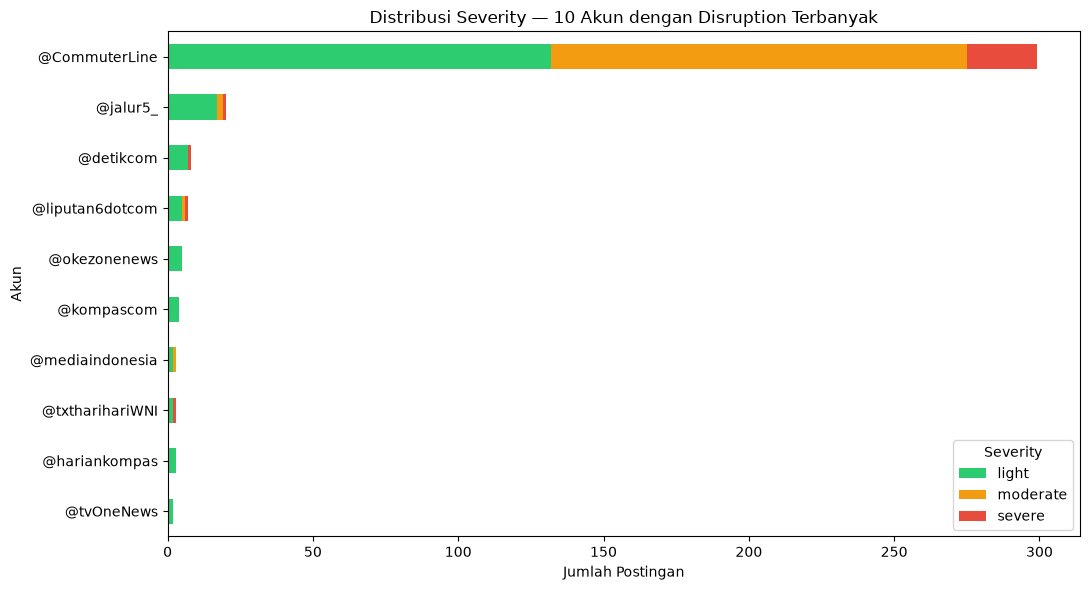

In [40]:
disruption_rows = df_model.loc[
    df_model["disruption_label"].eq("disruption")
]

severity_by_account = pd.crosstab(
    disruption_rows["account"],
    disruption_rows["severity"],
).reindex(
    columns=["light", "moderate", "severe"],
    fill_value=0,
)

top_accounts = (
    severity_by_account.sum(axis=1)
    .sort_values(ascending=False)
    .head(10)
    .index
)

ax = severity_by_account.loc[top_accounts].plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=["#2ECC71", "#F39C12", "#E74C3C"],
)

ax.set_title("Distribusi Severity — 10 Akun dengan Disruption Terbanyak")
ax.set_xlabel("Jumlah Postingan")
ax.set_ylabel("Akun")
ax.legend(title="Severity")
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [43]:
similarity_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    lowercase=False,
    sublinear_tf=True,
    max_features=100_000,
)

similarity_vectors = similarity_vectorizer.fit_transform(
    df_model["model_text"]
)

print("Jumlah teks:", similarity_vectors.shape[0])
print("Jumlah fitur audit:", similarity_vectors.shape[1])

Jumlah teks: 1311
Jumlah fitur audit: 76198


In [44]:
similarity_matrix = cosine_similarity(similarity_vectors)

upper_triangle = np.triu_indices(
    len(df_model),
    k=1,
)

pair_scores = similarity_matrix[upper_triangle]

In [45]:
similarity_results = []

for threshold in [0.85, 0.90, 0.95]:
    matching_pairs = pair_scores >= threshold

    involved_rows = np.unique(
        np.concatenate([
            upper_triangle[0][matching_pairs],
            upper_triangle[1][matching_pairs],
        ])
    )

    similarity_results.append({
        "threshold": threshold,
        "jumlah_pasangan": int(matching_pairs.sum()),
        "jumlah_teks_terlibat": len(involved_rows),
    })

similarity_summary = pd.DataFrame(similarity_results)

print(similarity_summary.to_string(index=False))

 threshold  jumlah_pasangan  jumlah_teks_terlibat
      0.85              163                   170
      0.90              107                   137
      0.95               49                    75


In [47]:
similarity_threshold = 0.90

adjacency_matrix = similarity_matrix >= similarity_threshold
np.fill_diagonal(adjacency_matrix, False)

group_count, group_ids = connected_components(
    csr_matrix(adjacency_matrix),
    directed=False,
    return_labels=True,
)

df_model["similarity_group"] = group_ids

print("Jumlah baris:", len(df_model))
print("Jumlah kelompok:", group_count)

Jumlah baris: 1311
Jumlah kelompok: 1231


In [48]:
group_sizes = (
    df_model.groupby("similarity_group")
    .size()
)

group_summary = pd.Series({
    "jumlah_baris": len(df_model),
    "jumlah_kelompok": len(group_sizes),
    "kelompok_satu_teks": group_sizes.eq(1).sum(),
    "kelompok_beberapa_teks": group_sizes.gt(1).sum(),
    "teks_dalam_kelompok_berulang": (
        group_sizes.loc[group_sizes.gt(1)].sum()
    ),
    "ukuran_kelompok_terbesar": group_sizes.max(),
})

print(group_summary.to_string())

jumlah_baris                    1311
jumlah_kelompok                 1231
kelompok_satu_teks              1174
kelompok_beberapa_teks            57
teks_dalam_kelompok_berulang     137
ukuran_kelompok_terbesar           7


In [49]:
severity_group_summary = (
    df_model.loc[
        df_model["disruption_label"].eq("disruption")
    ]
    .groupby("severity")
    .agg(
        jumlah_teks=("tweet_id", "size"),
        jumlah_kelompok=("similarity_group", "nunique"),
    )
    .reindex(["light", "moderate", "severe"])
)

print(severity_group_summary.to_string())

          jumlah_teks  jumlah_kelompok
severity                              
light             342              323
moderate          151              122
severe             66               60


In [51]:
strata = df_model["disruption_label"].where(
    df_model["disruption_label"].eq("not_disruption"),
    "disruption_" + df_model["severity"],
)

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

fold_ids = np.full(len(df_model), -1, dtype=int)

for fold_number, (_, fold_indices) in enumerate(
    splitter.split(
        X=df_model[["model_text"]],
        y=strata,
        groups=df_model["similarity_group"],
    )
):
    fold_ids[fold_indices] = fold_number

assert (fold_ids >= 0).all()

In [52]:
df_model["partition"] = "train"

df_model.loc[fold_ids == 0, "partition"] = "test"
df_model.loc[fold_ids == 1, "partition"] = "validation"

split_summary = (
    df_model["partition"]
    .value_counts()
    .reindex(["train", "validation", "test"])
    .to_frame("jumlah")
)

split_summary["persentase"] = (
    split_summary["jumlah"] / len(df_model) * 100
).round(2)

print(split_summary.to_string())

            jumlah  persentase
partition                     
train          786       59.95
validation     262       19.98
test           263       20.06


In [53]:
split_distribution = pd.crosstab(
    df_model["partition"],
    strata,
).reindex(
    index=["train", "validation", "test"],
    columns=[
        "not_disruption",
        "disruption_light",
        "disruption_moderate",
        "disruption_severe",
    ],
    fill_value=0,
)

print(split_distribution.to_string())

disruption_label  not_disruption  disruption_light  disruption_moderate  disruption_severe
partition                                                                                 
train                        450               206                   91                 39
validation                   151                68                   30                 13
test                         151                68                   30                 14


In [56]:
required_columns = {
    "tweet_id",
    "model_text",
    "similarity_group",
    "partition",
}

missing_columns = required_columns - set(df_model.columns)

print("Kolom yang belum tersedia:", sorted(missing_columns))

if not missing_columns:
    print("\nJumlah baris:", len(df_model))

    print("\nJumlah per partisi:")
    print(df_model["partition"].value_counts(dropna=False).to_string())

    print("\nContoh assignment yang sudah ada:")
    print(
        df_model[
            ["tweet_id", "similarity_group", "partition"]
        ].head(5).to_string(index=False)
    )

Kolom yang belum tersedia: []

Jumlah baris: 1311

Jumlah per partisi:
partition
train         786
test          263
validation    262

Contoh assignment yang sudah ada:
           tweet_id  similarity_group  partition
1683656326646497281                 0      train
1683657110834515970                 1      train
1683655390670774272                 2 validation
1664102616136298499                 3       test
1664092355413278721                 4       test


In [57]:
required_columns = [
    "tweet_id",
    "similarity_group",
    "partition",
]

assert df_model[required_columns].notna().all().all(), (
    "Ada ID, group, atau partition yang kosong."
)

assert df_model["partition"].isin(
    ["train", "validation", "test"]
).all(), "Ada nilai partition yang tidak dikenali."

group_partitions = (
    df_model.groupby("similarity_group")["partition"]
    .nunique()
)

leaked_groups = group_partitions[
    group_partitions > 1
].index

In [58]:
print("Total similarity groups:", len(group_partitions))
print("Groups crossing partitions:", len(leaked_groups))

if len(leaked_groups) > 0:
    print("\nContoh assignment kelompok bermasalah:")
    print(
        df_model.loc[
            df_model["similarity_group"].isin(leaked_groups),
            required_columns,
        ]
        .sort_values(["similarity_group", "partition", "tweet_id"])
        .head(20)
        .to_string(index=False)
    )

Total similarity groups: 1231
Groups crossing partitions: 0


In [59]:
account_normalized = (
    df_model["account"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.lstrip("@")
    .str.casefold()
)

source_audit = df_model.assign(
    is_commuterline=account_normalized.eq("commuterline")
)

In [60]:
source_split = (
    source_audit
    .groupby("partition")["is_commuterline"]
    .agg(total="size", commuterline="sum")
    .reindex(["train", "validation", "test"])
)

source_split["other_accounts"] = (
    source_split["total"] - source_split["commuterline"]
)

source_split["commuterline_pct"] = (
    source_split["commuterline"] / source_split["total"] * 100
).round(2)

print(source_split.to_string())

            total  commuterline  other_accounts  commuterline_pct
partition                                                        
train         786           411             375             52.29
validation    262           148             114             56.49
test          263           148             115             56.27


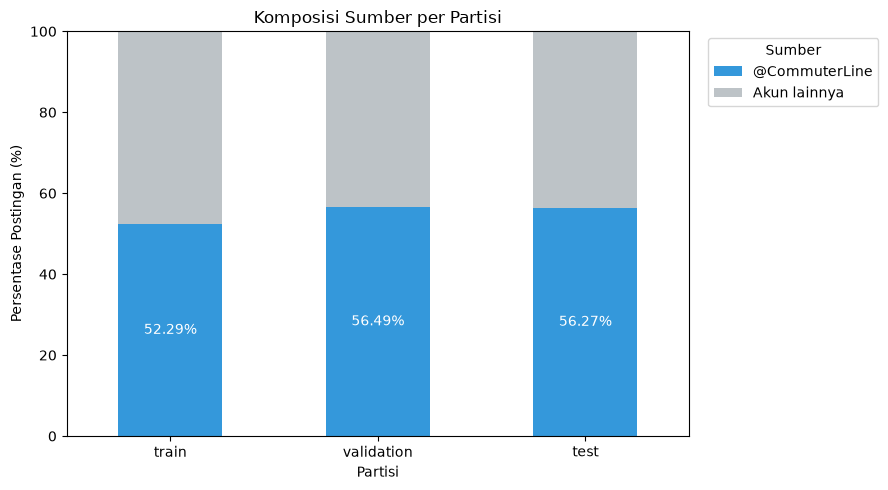

In [61]:
source_percentages = (
    source_split[["commuterline", "other_accounts"]]
    .div(source_split["total"], axis=0)
    .mul(100)
    .rename(columns={
        "commuterline": "@CommuterLine",
        "other_accounts": "Akun lainnya",
    })
)

ax = source_percentages.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#3498DB", "#BDC3C7"],
)

ax.set_title("Komposisi Sumber per Partisi")
ax.set_xlabel("Partisi")
ax.set_ylabel("Persentase Postingan (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Sumber", bbox_to_anchor=(1.02, 1), loc="upper left")

for position, percentage in enumerate(
    source_split["commuterline_pct"]
):
    ax.text(
        position,
        percentage / 2,
        f"{percentage:.2f}%",
        ha="center",
        va="center",
        color="white",
    )

plt.tight_layout()
plt.show()

In [62]:
event_audit_texts = (
    df_model["model_text"]
    .fillna("")
    .astype(str)
)

event_audit_vectorizer = TfidfVectorizer(
    analyzer="char",
    ngram_range=(3, 5),
    lowercase=False,
)

event_audit_vectors = (
    event_audit_vectorizer.fit_transform(event_audit_texts)
)

event_audit_similarities = (
    event_audit_vectors @ event_audit_vectors.T
).tocoo()

audit_partitions = df_model["partition"].to_numpy()
audit_groups = df_model["similarity_group"].to_numpy()

In [63]:
event_candidates = [
    (i, j, float(score))
    for i, j, score in zip(
        event_audit_similarities.row,
        event_audit_similarities.col,
        event_audit_similarities.data,
    )
    if i < j
    and audit_partitions[i] != audit_partitions[j]
    and audit_groups[i] != audit_groups[j]
    and score >= 0.75
]

event_candidates.sort(
    key=lambda pair: pair[2],
    reverse=True,
)

print(
    "Cross-partition candidate pairs:",
    len(event_candidates),
)

Cross-partition candidate pairs: 124


In [64]:
candidate_rows = []

for i, j, score in event_candidates[:10]:
    post_a = df_model.iloc[i]
    post_b = df_model.iloc[j]

    candidate_rows.append({
        "similarity": round(score, 3),
        "tweet_id_a": post_a["tweet_id"],
        "tweet_id_b": post_b["tweet_id"],
        "partition_a": post_a["partition"],
        "partition_b": post_b["partition"],
        "group_a": post_a["similarity_group"],
        "group_b": post_b["similarity_group"],
        "date_a": post_a["date"],
        "date_b": post_b["date"],
        "text_a": post_a["full_text"],
        "text_b": post_b["full_text"],
    })

event_candidate_table = pd.DataFrame(candidate_rows)

if event_candidate_table.empty:
    print("Tidak ditemukan pasangan yang memenuhi screening.")
else:
    with pd.option_context("display.max_colwidth", None):
        display(event_candidate_table)

,similarity,tweet_id_a,tweet_id_b,partition_a,partition_b,group_a,group_b,date_a,date_b,text_a,text_b
0,0.906,1212645969923149825,1212638809763926017,test,train,1225,1226,"Jan 2, 2020","Jan 2, 2020","Selamat sore, kami informasikan untuk rute tersebut perjalanan hanya sampai Stasiun Angke, dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks.","Selamat sore, kami informasikan untuk rute Bogor-Jatinegara perjalanan hanya sampai Stasiun Angke, dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1,0.905,2112766068330844307,2112734863443063093,test,train,1161,1162,Oct 21,Oct 21,"Hai, Kak. Mohon maaf atas keterlambatan perjalanan KA 5039D. Saat memasuki Stasiun Bekasi, perjalanan kereta perlu menunggu proses pergantian jalur dan sinyal aman untuk melanjutkan perjalanan. Kami memahami hal ini membuat waktu perjalanan Kakak menjadi lebih lama. Terima kasih atas kesabaran dan masukannya, Kak.","Hai, Kak. Mohon maaf ya, Kak, atas keterlambatan perjalanan KA 5057D. Saat memasuki Stasiun Manggarai, perjalanan kereta perlu menunggu proses pergantian jalur dan sinyal aman untuk melanjutkan perjalanan. Kami memahami hal ini membuat waktu perjalanan Kakak menjadi lebih lama. Terima kasih atas kesabaran dan masukannya, Kak. 🙏"
2,0.901,1212677650403037185,1212673792964608001,validation,train,1223,1224,"Jan 2, 2020","Jan 2, 2020","Selamat sore, kami informasikan untuk saat ini dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks.","Selamat sore, kami informasikan untuk rute tersebut dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
3,0.900,606769089038516225,606754014735106048,train,test,1141,1142,"Jun 5, 2015","Jun 5, 2015",Mohon Maaf perjalanan anda terganggu di karna adanya Antrian Commuter Line antara Stasiun Gambir-Stasiun Manggarai,@gidgul Mohon Maaf perjalanan anda terganggu di karna adanya Antrian Commuter Line antara Stasiun Gambir-Stasiun Manggarai
4,0.898,2121759081040101685,2120808192213123456,train,test,388,533,4 hours ago,Nov 12,Please be considerate of those around you! Smoking or vaping inside stations and on trains is strictly prohibited.,Please be considerate of those around you! Smoking or vaping inside station and train areas is strictly prohibited.
5,0.896,2031726860535767405,2031725175012831652,test,train,1159,1160,"Mar 11, 2026","Mar 11, 2026","Selamat malam, Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Bogor–Jakarta Kota saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Tks. 🙏","Selamat malam, Kak. Mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) yang berdampak pada perjalanan Commuter Line rute Bogor–Jakarta Kota saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Terima kasih. 🙏"
6,0.895,2056563451166884237,2054012385825075232,train,validation,1174,1179,May 19,May 12,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk KA 5053B (Bekasi-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks.","Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengeceka

In [65]:
suspected_events = {
    "Banjir Kampung Bandan 2020": [
        "1212645969923149825",
        "1212638809763926017",
        "1212677650403037185",
        "1212673792964608001",
        "1212629661194178560",
        "1212607374038425601",
    ],
    "Antrean Gambir-Manggarai 2015": [
        "606769089038516225",
        "606754014735106048",
    ],
    "LAA Bojong Gede-Citayam 2026": [
        "2031726860535767405",
        "2031725175012831652",
        "2031731033159373220",
    ],
    "KA 1382 Tanjung Barat": [
        "2108547267661905984",
        "2108537391783002252",
    ],
}

event_lookup = {
    tweet_id: event
    for event, ids in suspected_events.items()
    for tweet_id in ids
}

In [66]:
event_audit = df_model.copy()

event_audit["tweet_id_key"] = (
    event_audit["tweet_id"].astype(str).str.strip()
)

event_audit = event_audit.loc[
    event_audit["tweet_id_key"].isin(event_lookup)
].copy()

event_audit["candidate_event"] = (
    event_audit["tweet_id_key"].map(event_lookup)
)

missing_ids = sorted(
    set(event_lookup) - set(event_audit["tweet_id_key"])
)

print("Jumlah ID kandidat:", len(event_lookup))
print("Jumlah ID ditemukan:", event_audit["tweet_id_key"].nunique())
print("ID tidak ditemukan:", missing_ids)

display(
    event_audit[[
        "candidate_event",
        "tweet_id",
        "partition",
        "similarity_group",
        "disruption_label",
        "severity",
        "date",
        "account",
    ]].sort_values(["candidate_event", "partition", "tweet_id"])
)

Jumlah ID kandidat: 13
Jumlah ID ditemukan: 13
ID tidak ditemukan: []


,candidate_event,tweet_id,partition,similarity_group,disruption_label,severity,date,account
1196,Antrean Gambir-Manggarai 2015,606754014735106048,test,1142,disruption,light,"Jun 5, 2015",@CommuterLine
1195,Antrean Gambir-Manggarai 2015,606769089038516225,train,1141,disruption,light,"Jun 5, 2015",@CommuterLine
1301,Banjir Kampung Bandan 2020,1212645969923149825,test,1225,disruption,light,"Jan 2, 2020",@CommuterLine
1305,Banjir Kampung Bandan 2020,1212607374038425601,train,1229,disruption,light,"Jan 2, 2020",@CommuterLine
1302,Banjir Kampung Bandan 2020,1212638809763926017,train,1226,disruption,light,"Jan 2, 2020",@CommuterLine
1300,Banjir Kampung Bandan 2020,1212673792964608001,train,1224,disruption,light,"Jan 2, 2020",@CommuterLine
1303,Banjir Kampung Bandan 2020,1212629661194178560,validation,1227,disruption,light,"Jan 2, 2020",@CommuterLine
1299,Banjir Kampung Bandan 2020,1212677650403037185,validation,1223,disruption,light,"Jan 2, 2020",@CommuterLine
1060,KA 1382 Tanjung Barat,2108547267661905984,train,1030,disruption,light,Oct 9,@CommuterLine
1064,KA 1382 Tanjung Barat,2108537391783002252,validation,1033,disruption,light,Oct 9,@CommuterLine


In [67]:
event_summary = (
    event_audit.groupby("candidate_event")
    .agg(
        jumlah_postingan=("tweet_id_key", "nunique"),
        jumlah_partisi=("partition", "nunique"),
        partisi=("partition", lambda values: ", ".join(sorted(set(values)))),
        variasi_relevance=("disruption_label", "nunique"),
    )
)

disruption_event_audit = event_audit.loc[
    event_audit["disruption_label"].eq("disruption")
]

event_summary["jumlah_partisi_disruption"] = (
    disruption_event_audit.groupby("candidate_event")["partition"]
    .nunique()
    .reindex(event_summary.index, fill_value=0)
)

event_summary["variasi_severity_disruption"] = (
    disruption_event_audit.groupby("candidate_event")["severity"]
    .nunique()
    .reindex(event_summary.index, fill_value=0)
)

display(event_summary)

,jumlah_postingan,jumlah_partisi,partisi,variasi_relevance,jumlah_partisi_disruption,variasi_severity_disruption
candidate_event,,,,,,
Antrean Gambir-Manggarai 2015,2,2,"test, train",1,2,1
Banjir Kampung Bandan 2020,6,3,"test, train, validation",1,3,1
KA 1382 Tanjung Barat,2,2,"train, validation",1,2,1
LAA Bojong Gede-Citayam 2026,3,2,"test, train",1,2,1


In [68]:
previous_event_lookup = {
    str(tweet_id).strip(): event
    for event, ids in suspected_events.items()
    for tweet_id in ids
}

In [69]:
remaining_candidates = []

for i, j, score in event_candidates:
    post_a = df_model.iloc[i]
    post_b = df_model.iloc[j]

    id_a = str(post_a["tweet_id"]).strip()
    id_b = str(post_b["tweet_id"]).strip()

    if (
        id_a in previous_event_lookup
        and id_b in previous_event_lookup
        and previous_event_lookup[id_a]
        == previous_event_lookup[id_b]
    ):
        continue

    remaining_candidates.append({
        "similarity": score,
        "tweet_id_a": id_a,
        "tweet_id_b": id_b,
        "partition_a": post_a["partition"],
        "partition_b": post_b["partition"],
        "group_a": post_a["similarity_group"],
        "group_b": post_b["similarity_group"],
        "date_a": post_a["date"],
        "date_b": post_b["date"],
        "relevance_a": post_a["disruption_label"],
        "relevance_b": post_b["disruption_label"],
        "severity_a": post_a["severity"],
        "severity_b": post_b["severity"],
        "text_a": post_a["full_text"],
        "text_b": post_b["full_text"],
    })

In [70]:
remaining_df = pd.DataFrame(remaining_candidates)

print("Remaining candidate pairs:", len(remaining_df))

if remaining_df.empty:
    print("Tidak ada pasangan tersisa dari screening ini.")
else:
    remaining_df = (
        remaining_df
        .sort_values("similarity", ascending=False)
        .reset_index(drop=True)
    )

    with pd.option_context("display.max_colwidth", None):
        display(remaining_df.head(15).round({"similarity": 3}))

Remaining candidate pairs: 111


,similarity,tweet_id_a,tweet_id_b,partition_a,partition_b,group_a,group_b,date_a,date_b,relevance_a,relevance_b,severity_a,severity_b,text_a,text_b
0,0.905,2112766068330844307,2112734863443063093,test,train,1161,1162,Oct 21,Oct 21,disruption,disruption,moderate,moderate,"Hai, Kak. Mohon maaf atas keterlambatan perjalanan KA 5039D. Saat memasuki Stasiun Bekasi, perjalanan kereta perlu menunggu proses pergantian jalur dan sinyal aman untuk melanjutkan perjalanan. Kami memahami hal ini membuat waktu perjalanan Kakak menjadi lebih lama. Terima kasih atas kesabaran dan masukannya, Kak.","Hai, Kak. Mohon maaf ya, Kak, atas keterlambatan perjalanan KA 5057D. Saat memasuki Stasiun Manggarai, perjalanan kereta perlu menunggu proses pergantian jalur dan sinyal aman untuk melanjutkan perjalanan. Kami memahami hal ini membuat waktu perjalanan Kakak menjadi lebih lama. Terima kasih atas kesabaran dan masukannya, Kak. 🙏"
1,0.898,2121759081040101685,2120808192213123456,train,test,388,533,4 hours ago,Nov 12,not_disruption,not_disruption,,,Please be considerate of those around you! Smoking or vaping inside stations and on trains is strictly prohibited.,Please be considerate of those around you! Smoking or vaping inside station and train areas is strictly prohibited.
2,0.895,2056563451166884237,2054012385825075232,train,validation,1174,1179,May 19,May 12,disruption,disruption,moderate,moderate,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk KA 5053B (Bekasi-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks.","Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk KA 5055C (Cikarang-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks."
3,0.887,2019754276529316064,2017241386240864659,validation,train,1088,1094,Feb 6,Jan 30,disruption,disruption,moderate,moderate,"Selamat malam Kak. Berdasarkan informasi yang kami terima, perjalanan KA 5148B (Angke—Cikarang via Manggarai) tertahan di Stasiun Bekasi karena adanya pergantian jalur dengan KA Jarak Jauh dan menunggu aman perlintasan sebidang di dekat Stasiun Bekasi dampak adanya kepadatan lalu lintas. Kami mohon maaf atas ketidaknyamanan yang Kakak alami sebelumnya.🙏","Selamat malam Kak. Berdasarkan informasi yang kami terima, perjalanan KA 6066B (Kampung Bandan—Cikarang via Manggarai) tertahan di Stasiun Bekasi karena adanya pergantian jalur dengan KA Jarak Jauh dan menunggu aman perlintasan sebidang di dekat Stasiun Bekasi dampak adanya kepadatan lalu lintas. Kami mohon maaf atas ketidaknyamanan yang Kakak alami sebelumnya.🙏"
4,0.885,2104961430542017018,2044546488639111667,train,test,223,253,Sep 29,Apr 16,not_disruption,not_disruption,,,📢 Info Commuter!,📢 Info Commuter
5,0.881,2024992349101912250,2024987869010690154,train,validation,1184,1185,Feb 21,Feb 21,disruption,disruption,moderate,moderate,"Selamat pagi dan mohon maaf ya Kak. Perjalanan Commuter Line Lintas Cikarang/Bekasi pagi ini mengalami selisih waktu dari jadwal yang ditentukan, karena imbas adanya pekerjaan Pergeseran Wesel Stasiun Bekasi, sehingga perjalanan Commuter Line menunggu sinyal aman masuk/keluar stasiun guna memastikan keamanan serta keselamatan pelanggan. Sekali lagi kami mohon maaf atas ketidaknyamanannya ya Kak. Tks.","Selamat pagi dan mohon maaf ya Kak. Perjalanan Commuter Line KA 5018B (Kampung Bandan-Manggarai-Cikarang) mengalami selisih waktu dari jadwal yang ditentukan, karena imbas adanya pekerjaan Pergeseran Wesel Stasiun Bekasi, sehingga perjalanan Commuter Line menunggu sinyal aman masuk/keluar stasiun guna memastikan keamanan serta keselamatan pelanggan. Sekali lagi kami mohon maaf atas ketidaknyamanannya ya Kak. Tks."
6,0.880,1212

In [72]:
candidate_parent = {}

def candidate_find(index):
    candidate_parent.setdefault(index, index)

    while candidate_parent[index] != index:
        candidate_parent[index] = candidate_parent[
            candidate_parent[index]
        ]
        index = candidate_parent[index]

    return index


def candidate_union(index_a, index_b):
    root_a = candidate_find(index_a)
    root_b = candidate_find(index_b)

    if root_a != root_b:
        candidate_parent[root_b] = root_a


for i, j, score in event_candidates:
    candidate_union(int(i), int(j))

In [73]:
candidate_clusters = defaultdict(list)

for index in list(candidate_parent):
    root = candidate_find(index)
    candidate_clusters[root].append(index)

candidate_edge_counts = defaultdict(int)

for i, j, score in event_candidates:
    root = candidate_find(int(i))
    candidate_edge_counts[root] += 1

cluster_rows = []

for root, indices in candidate_clusters.items():
    indices = sorted(indices)
    subset = df_model.iloc[indices]

    cluster_rows.append({
        "cluster_key": min(
            subset["tweet_id"].astype(str).str.strip()
        ),
        "posts": len(indices),
        "candidate_pairs": candidate_edge_counts[root],
        "partitions": ", ".join(
            sorted(subset["partition"].unique())
        ),
        "sample_text": str(subset.iloc[0]["full_text"])[:120],
    })

In [74]:
cluster_summary = pd.DataFrame(
    cluster_rows,
    columns=[
        "cluster_key",
        "posts",
        "candidate_pairs",
        "partitions",
        "sample_text",
    ],
)

if not cluster_summary.empty:
    cluster_summary = (
        cluster_summary
        .sort_values(
            ["posts", "candidate_pairs", "cluster_key"],
            ascending=[False, False, True],
        )
        .reset_index(drop=True)
    )

assert cluster_summary["posts"].sum() == len(candidate_parent)
assert (
    cluster_summary["candidate_pairs"].sum()
    == len(event_candidates)
)

print("Total candidate pairs:", len(event_candidates))
print("Total candidate clusters:", len(cluster_summary))
print("Total unique posts involved:", len(candidate_parent))

display(cluster_summary.head(15))

Total candidate pairs: 124
Total candidate clusters: 35
Total unique posts involved: 120


,cluster_key,posts,candidate_pairs,partitions,sample_text
0,2031724944586141768,11,28,"test, train",Selamat malam Kak. Mohon maaf baru terbalaskan...
1,1212571087558471680,10,17,"test, train, validation","Selamat sore, kami informasikan untuk saat ini..."
2,2054010080199352486,7,12,"test, train, validation","Selamat pagi, Kak. Mohon maaf atas ketidaknyam..."
3,2008525783699194324,6,8,"test, train, validation","Selamat malam, Kak. Perjalanan Commuter Line t..."
4,2113536666208284948,6,8,"train, validation","Selamat sore, Kak. Mohon maaf atas keterlambat..."
5,2108537391783002252,6,5,"train, validation","Selamat malam, Kak. Mohon maaf atas keterlamba..."
6,1728269712797376987,5,4,"test, train","Selamat siang kak, sehubungan dengan adanya pe..."
7,2013785776115589276,5,4,"test, train","Selamat pagi, Kak. Guna kami lakukan pengeceka..."
8,2089488655299789069,5,4,"test, validation","Selamat pagi, Kak. Perjalanan Commuter Line li..."
9,2120536052750573848,4,4,"train, validation",Selamat malam Kak. Informasi lengkap jadwal C...


In [75]:
assert not cluster_summary.empty, "Tidak ada candidate cluster."

target_key = str(cluster_summary.iloc[0]["cluster_key"])

selected_indices = next(
    sorted(indices)
    for indices in candidate_clusters.values()
    if min(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    ) == target_key
)

review_cluster = df_model.iloc[selected_indices].copy()

In [77]:
print("Cluster:", target_key)
print("Jumlah postingan:", len(review_cluster))
print(
    "Partisi:",
    review_cluster["partition"].value_counts().to_dict(),
)

expected_posts = int(cluster_summary.iloc[0]["posts"])

assert len(review_cluster) == expected_posts, (
    "Jumlah anggota tidak cocok dengan cluster_summary."
)

Cluster: 2031724944586141768
Jumlah postingan: 11
Partisi: {'test': 7, 'train': 4}


In [78]:
review_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        review_cluster[review_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1224,2031724944586141768,test,1159,"Mar 11, 2026",@CommuterLine,disruption,light,"Selamat malam Kak. Mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Nambo saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas. Tks.🙏"
1222,2031726860535767405,test,1159,"Mar 11, 2026",@CommuterLine,disruption,moderate,"Selamat malam, Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Bogor–Jakarta Kota saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Tks. 🙏"
1221,2031729520676639220,test,1159,"Mar 11, 2026",@CommuterLine,disruption,moderate,"Selamat malam, Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Bogor–Jakarta Kota (PP) saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Tks. 🙏"
1220,2031730575078551705,test,1159,"Mar 11, 2026",@CommuterLine,disruption,moderate,"Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Bogor–Jakarta Kota (PP) saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Tks."
1218,2031731713223876922,test,1159,"Mar 11, 2026",@CommuterLine,disruption,moderate,"Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Nambo saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Tks. 🙏"
1217,2031735691739295988,test,1159,"Mar 11, 2026",@CommuterLine,disruption,moderate,"Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Bogor (PP) saat ini telah selesai ditangani oleh petugas. Jalur di lokasi gangguan sudah dapat dilalui kembali, namun perjalanan kereta masih dalam proses penguraian kepadatan di lintas sehingga beberapa perjalanan masih mengalami keterlambatan. Tks. 🙏"
1216,2031736105716847068,test,1159,"Mar 11, 2026",@CommuterLine,disruption,moderate,"Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informasikan bahwa gangguan operasional pada Listrik Aliran Atas (LAA) di antara Stasiun Bojong Gede–Citayam yang berdampak pada perjalanan Commuter Line rute Jakarta Kota–Nambo saat ini telah selesai ditangani oleh petugas. Jalu

In [79]:
assert len(cluster_summary) >= 2, (
    "Candidate cluster kurang dari dua."
)

second_target_key = str(
    cluster_summary.iloc[1]["cluster_key"]
)

second_indices = next(
    sorted(indices)
    for indices in candidate_clusters.values()
    if min(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    ) == second_target_key
)

review_cluster_second = df_model.iloc[second_indices].copy()

In [80]:
print("Cluster:", second_target_key)
print("Jumlah postingan:", len(review_cluster_second))

print(
    "Partisi:",
    review_cluster_second["partition"]
    .value_counts()
    .to_dict(),
)

print(
    "Severity:",
    review_cluster_second["severity"]
    .replace("", "(tidak berlaku)")
    .value_counts(dropna=False)
    .to_dict(),
)

assert len(review_cluster_second) == int(
    cluster_summary.iloc[1]["posts"]
), "Jumlah anggota tidak cocok dengan cluster_summary."

Cluster: 1212571087558471680
Jumlah postingan: 10
Partisi: {'validation': 5, 'train': 4, 'test': 1}
Severity: {'light': 10}


In [81]:
second_review_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        review_cluster_second[second_review_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1301,1212645969923149825,test,1225,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat sore, kami informasikan untuk rute tersebut perjalanan hanya sampai Stasiun Angke, dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1307,1212578846785986565,train,1229,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat siang, kami informasikan perjalanan hanya sampai St Angke, dampak adanya genangan air antara St Kp Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1305,1212607374038425601,train,1229,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat siang, kami informasikan untuk tujuan Jatinegara perjalanan hanya sampai St Angke, dampak adanya genangan air antara St Kp Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1302,1212638809763926017,train,1226,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat sore, kami informasikan untuk rute Bogor-Jatinegara perjalanan hanya sampai Stasiun Angke, dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1300,1212673792964608001,train,1224,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat sore, kami informasikan untuk rute tersebut dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1308,1212571087558471680,validation,1228,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat pagi, dampak adanya genangan air antara St Kp Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1306,1212600975690625024,validation,1228,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat siang, dampak adanya genangan air antara St Kp Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."
1304,1212628288604008449,validation,1228,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat siang, dampak adanya genangan air antara St Kp Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA."
1303,1212629661194178560,validation,1227,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat siang, kami informasikan untuk rute Bogor-Jatinegara perjalanan hanya sampai St Angke, dampak adanya genangan air antara St Kp Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA"
1299,1212677650403037185,validation,1223,"Jan 2, 2020",@CommuterLine,disruption,light,"Selamat sore, kami informasikan untuk saat ini dampak adanya genangan air antara Stasiun Kampung Bandan-Kemayoran untuk perjalanan belum dapat dilalui KA, tks."


In [82]:
third_target_key = "2054010080199352486"

third_summary = cluster_summary.loc[
    cluster_summary["cluster_key"].astype(str).eq(third_target_key)
]

assert len(third_summary) == 1, (
    "Cluster key tidak ditemukan atau tidak unik."
)

third_indices = next(
    sorted(indices)
    for indices in candidate_clusters.values()
    if min(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    ) == third_target_key
)

review_cluster_third = df_model.iloc[third_indices].copy()

In [83]:
print("Cluster:", third_target_key)
print("Jumlah postingan:", len(review_cluster_third))

print(
    "Partisi:",
    review_cluster_third["partition"].value_counts().to_dict(),
)

print(
    "Severity:",
    review_cluster_third["severity"]
    .replace("", "(tidak berlaku)")
    .value_counts(dropna=False)
    .to_dict(),
)

assert len(review_cluster_third) == int(
    third_summary.iloc[0]["posts"]
), "Jumlah anggota tidak cocok dengan cluster_summary."

Cluster: 2054010080199352486
Jumlah postingan: 7
Partisi: {'train': 4, 'validation': 2, 'test': 1}
Severity: {'moderate': 7}


In [84]:
third_review_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        review_cluster_third[third_review_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1249,2054010080199352486,test,1180,May 12,@CommuterLine,disruption,moderate,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk perjalanan KA 5059B (Bekasi-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks.\nfrom:CommuterLine sinyal - Search / X"
1247,2054017531300737394,train,1176,May 12,@CommuterLine,disruption,moderate,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Perjalanan Commuter Line lintas Bekasi/Cikarang mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks."
1245,2054070762802409825,train,1178,May 12,@CommuterLine,disruption,moderate,"Selamat siang, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk perjalanan KA 5036C (Angke-Manggarai-Bekasi) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks."
1243,2054079406055031151,train,1174,May 12,@CommuterLine,disruption,moderate,"Selamat siang, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk KA 5041C (Bekasi-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks."
1239,2056563451166884237,train,1174,May 19,@CommuterLine,disruption,moderate,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk KA 5053B (Bekasi-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks."
1248,2054012385825075232,validation,1179,May 12,@CommuterLine,disruption,moderate,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk KA 5055C (Cikarang-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Tks."
1246,2054032245867069931,validation,1179,May 12,@CommuterLine,disruption,moderate,"Selamat pagi Kak. Setelah Kami bantu lakukan pengecekan untuk KA 5039C (Cikarang-Manggarai-Angke) mengalami keterlambatan imbas dari adanya pergantian jalur dan sinyal aman untuk melintas, sehingga terdapat selisih waktu perjalanan dari jadwal yang sudah ditentukan ya, Kak. Mohon maaf atas ketidaknyamanannya. Tks."


In [85]:
cluster_members_lookup = {
    min(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    ): sorted(indices)
    for indices in candidate_clusters.values()
}

In [86]:
review_rows = []

for number, (_, item) in enumerate(
    cluster_summary.iterrows(),
    start=1,
):
    key = str(item["cluster_key"])
    indices = cluster_members_lookup[key]
    subset = df_model.iloc[indices]

    assert len(subset) == int(item["posts"]), (
        f"Jumlah anggota cluster {key} tidak sesuai."
    )

    dates = subset["date"].fillna("").astype(str).str.strip()
    severities = (
        subset["severity"]
        .fillna("")
        .replace("", "(tidak berlaku)")
    )

    review_rows.append({
        "cluster": number,
        "cluster_key": key,
        "posts": len(subset),
        "partition_count": subset["partition"].nunique(),
        "partitions": ", ".join(
            sorted(subset["partition"].unique())
        ),
        "date_value_count": dates.loc[dates.ne("")].nunique(),
        "dates": " | ".join(
            sorted(dates.loc[dates.ne("")].unique())
        ),
        "relevance": ", ".join(
            sorted(subset["disruption_label"].unique())
        ),
        "severity": ", ".join(sorted(severities.unique())),
        "sample": str(subset.iloc[0]["full_text"])[:100],
    })

In [87]:
review_summary = pd.DataFrame(review_rows)

print("Jumlah candidate clusters:", len(review_summary))

with pd.option_context(
    "display.max_rows", None,
    "display.max_colwidth", None,
):
    display(review_summary)

Jumlah candidate clusters: 35


,cluster,cluster_key,posts,partition_count,partitions,date_value_count,dates,relevance,severity,sample
0,1,2031724944586141768,11,2,"test, train",1,"Mar 11, 2026",disruption,"light, moderate",Selamat malam Kak. Mohon maaf baru terbalaskan dan mohon maaf atas ketidaknyamanannya. Kami informas
1,2,1212571087558471680,10,3,"test, train, validation",1,"Jan 2, 2020",disruption,light,"Selamat sore, kami informasikan untuk saat ini dampak adanya genangan air antara Stasiun Kampung Ban"
2,3,2054010080199352486,7,3,"test, train, validation",2,May 12 | May 19,disruption,moderate,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Setelah Kami bantu lakukan pengecekan untuk K"
3,4,2008525783699194324,6,3,"test, train, validation",3,Feb 6 | Jan 30 | Jan 6,disruption,moderate,"Selamat malam, Kak. Perjalanan Commuter Line tujuan Cikarang tertahan di Stasiun Bekasi karena ada"
4,5,2113536666208284948,6,2,"train, validation",1,Oct 23,disruption,moderate,"Selamat sore, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Cikarang tersebut,"
5,6,2108537391783002252,6,2,"train, validation",1,Oct 9,disruption,light,"Selamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan"
6,7,1728269712797376987,5,2,"test, train",1,"Nov 25, 2023",disruption,moderate,"Selamat siang kak, sehubungan dengan adanya pekerjaan switch over penggantian prasarana perkeretaapi"
7,8,2013785776115589276,5,2,"test, train",3,Feb 18 | Feb 3 | Jan 21,disruption,light,"Selamat pagi, Kak. Guna kami lakukan pengecekan, mohon beritahu nomor KA atau rute dan jadwal perjal"
8,9,2089488655299789069,5,2,"test, validation",2,"Aug 18 | Aug 18, 2026",disruption,severe,"Selamat pagi, Kak. Perjalanan Commuter Line lintas Cikarang-Kampung Bandan PP sempat tertahan imba"
9,10,2120536052750573848,4,2,"train, validation",2,Nov 11 | Nov 13,not_disruption,(tidak berlaku),"Selamat malam Kak. Informasi lengkap jadwal Commuter Line dapat dilihat melalui link :\n, aplikasi"


In [88]:
target_tweet_id = "2089488655299789069"

matching_clusters = [
    sorted(indices)
    for indices in candidate_clusters.values()
    if target_tweet_id in set(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    )
]

assert len(matching_clusters) == 1, (
    "ID target tidak ditemukan atau muncul dalam beberapa cluster."
)

target_review_cluster = df_model.iloc[
    matching_clusters[0]
].copy()

In [89]:
print("Target tweet ID:", target_tweet_id)
print("Jumlah postingan:", len(target_review_cluster))

print(
    "Partisi:",
    target_review_cluster["partition"]
    .value_counts()
    .to_dict(),
)

print(
    "Severity:",
    target_review_cluster["severity"]
    .replace("", "(tidak berlaku)")
    .value_counts(dropna=False)
    .to_dict(),
)

Target tweet ID: 2089488655299789069
Jumlah postingan: 5
Partisi: {'validation': 4, 'test': 1}
Severity: {'severe': 5}


In [90]:
target_review_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        target_review_cluster[target_review_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1094,2089497284551832032,test,1059,"Aug 18, 2026",@CommuterLine,disruption,severe,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Perjalanan Commuter Line lintas Cikarang-Kampung Bandan PP sempat tertahan imbas adanya truk mogok di perlintasan antara Tambun-Bekasi Timur, saat ini telah selesai evakuasi dan KA dalam proses penguraian kepadatan. Sehingga perjalanan KA 6007 (Cikarang-Pasar Senen-Kampung Bandan) mengalami selisih waktu keberangkatan dari yang terjadwalkan ya. Tks.🙏"
1097,2089488655299789069,validation,1058,Aug 18,@CommuterLine,disruption,severe,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Perjalanan Commuter Line lintas Cikarang-Kampung Bandan PP sempat tertahan imbas adanya truk mogok di perlintasan antara Tambun-Bekasi Timur, saat ini truk mogok tersebut telah selesai dievakuasi dan KA dalam proses penguraian kepadatan. Tks."
1096,2089490634700898347,validation,1058,Aug 18,@CommuterLine,disruption,severe,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Perjalanan Commuter Line lintas Cikarang-Kampung Bandan PP sempat tertahan imbas adanya truk mogok di perlintasan antara Tambun-Bekasi Timur, saat ini telah selesai evakuasi dan KA dalam proses penguraian kepadatan. Tks."
1095,2089495893024338221,validation,1058,Aug 18,@CommuterLine,disruption,severe,"Selamat pagi, Kak. Mohon maaf atas ketidaknyamanannya. Perjalanan Commuter Line lintas Cikarang-Kampung Bandan PP sempat tertahan imbas adanya truk mogok di perlintasan antara Tambun-Bekasi Timur, saat ini telah selesai evakuasi dan KA dalam proses penguraian kepadatan. Tks.🙏"
1093,2089524849974911103,validation,1058,Aug 18,@CommuterLine,disruption,severe,"Selamat pagi, Kak. Perjalanan Commuter Line lintas Cikarang-Kampung Bandan PP sempat tertahan imbas adanya truk mogok di perlintasan antara Tambun-Bekasi Timur, saat ini telah selesai evakuasi dan KA dalam proses penguraian kepadatan. Tks."


In [94]:
cluster_five_target_id = "2113536666208284948"

cluster_five_matches = [
    sorted(indices)
    for indices in candidate_clusters.values()
    if cluster_five_target_id in set(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    )
]

assert len(cluster_five_matches) == 1, (
    "ID target tidak ditemukan atau muncul dalam beberapa cluster."
)

review_cluster_five = df_model.iloc[
    cluster_five_matches[0]
].copy()

In [95]:
print("Target tweet ID:", cluster_five_target_id)
print("Jumlah postingan:", len(review_cluster_five))

print(
    "Partisi:",
    review_cluster_five["partition"].value_counts().to_dict(),
)

print(
    "Severity:",
    review_cluster_five["severity"]
    .replace("", "(tidak berlaku)")
    .value_counts(dropna=False)
    .to_dict(),
)

Target tweet ID: 2113536666208284948
Jumlah postingan: 6
Partisi: {'validation': 4, 'train': 2}
Severity: {'moderate': 6}


In [96]:
cluster_five_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        review_cluster_five[cluster_five_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1057,2113536666208284948,train,1027,Oct 23,@CommuterLine,disruption,moderate,"Selamat siang, Kak. Perjalanan Commuter Line lintas Cikarang tersebut mengalami pergantian jalur dan terdapat selisih waktu dari jadwal keberangkatan, sehubungan sempat adanya gangguan operasional pada wesel di Stasiun Jatinegara. Karel mohon maaf atas ketidaknyamanannya. Trims."
1054,2113542000691806326,train,1027,Oct 23,@CommuterLine,disruption,moderate,"Selamat sore, Kak. Perjalanan Commuter Line lintas Cikarang tersebut mengalami pergantian jalur dan terdapat selisih waktu dari jadwal keberangkatan, sehubungan sempat adanya gangguan operasional pada wesel di Stasiun Jatinegara. Karel mohon maaf atas ketidaknyamanannya. Trims."
1056,2113538923796545742,validation,639,Oct 23,@CommuterLine,disruption,moderate,"Selamat siang. Karel mohon maaf atas keterlambatan perjalanan Commuter Line lintas Cikarang tersebut, sehubungan sempat adanya gangguan operasional pada wesel di Stasiun Jatinegara. Hal tersebut menyebabkan perjalanan Commuter Line yang melintas mengalami antrean pergantian jalur dan terdapat selisih waktu dari jadwal keberangkatan. Trims."
1055,2113540224689267094,validation,1028,Oct 23,@CommuterLine,disruption,moderate,"Selamat siang dan mohon maaf baru terbalaskan ya. Perjalanan Commuter Line lintas Cikarang tersebut mengalami pergantian jalur dan terdapat selisih waktu dari jadwal keberangkatan, sehubungan sempat adanya gangguan operasional pada wesel di Stasiun Jatinegara. Trims."
1053,2113542570563490051,validation,639,Oct 23,@CommuterLine,disruption,moderate,"Selamat sore. Karel mohon maaf atas keterlambatan perjalanan Commuter Line lintas Cikarang tersebut, sehubungan sempat adanya gangguan operasional pada wesel di Stasiun Jatinegara. Hal tersebut menyebabkan perjalanan Commuter Line yang melintas mengalami antrean pergantian jalur dan terdapat selisih waktu dari jadwal keberangkatan. Trims."
665,2113544724133151007,validation,639,Oct 23,@CommuterLine,disruption,moderate,"Selamat sore, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Cikarang tersebut, sehubungan sempat adanya gangguan operasional pada wesel di Stasiun Jatinegara. Hal tersebut menyebabkan perjalanan Commuter Line yang melintas mengalami antrean pergantian jalur dan terdapat selisih waktu dari jadwal keberangkatan. Trims."


In [97]:
cluster_seven_target_id = "1728269712797376987"

cluster_seven_matches = [
    sorted(indices)
    for indices in candidate_clusters.values()
    if cluster_seven_target_id in set(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    )
]

assert len(cluster_seven_matches) == 1, (
    "ID target tidak ditemukan atau muncul dalam beberapa cluster."
)

review_cluster_seven = df_model.iloc[
    cluster_seven_matches[0]
].copy()

In [98]:
print("Target tweet ID:", cluster_seven_target_id)
print("Jumlah postingan:", len(review_cluster_seven))

print(
    "Partisi:",
    review_cluster_seven["partition"].value_counts().to_dict(),
)

print(
    "Severity:",
    review_cluster_seven["severity"]
    .replace("", "(tidak berlaku)")
    .value_counts(dropna=False)
    .to_dict(),
)

Target tweet ID: 1728269712797376987
Jumlah postingan: 5
Partisi: {'train': 4, 'test': 1}
Severity: {'moderate': 5}


In [99]:
cluster_seven_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        review_cluster_seven[cluster_seven_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1165,1728276098696491051,test,1117,"Nov 25, 2023",@CommuterLine,disruption,moderate,"Selamat siang kak, sehubungan dengan adanya pekerjaan switch over penggantian prasarana perkeretaapian di Stasiun Tambun, kami mohon maaf perjalanan Commuter Line Bekasi/Cikarang terganggu dan dilakukan rekayasa pola operasi. Kami imbau agar #RekanCommuters selalu mengikuti arahan petugas di area stasiun dan dapat menyesuaikan kembali waktu perjalanannya dengan melihat jadwal melalui aplikasi C-Access atau informasi terbaru melalui timeline kami, tks."
1169,1728269712797376987,train,1113,"Nov 25, 2023",@CommuterLine,disruption,moderate,"Selamat siang kak, sehubungan dengan adanya pekerjaan switch over penggantian prasarana perkeretaapian di Stasiun Tambun, kami mohon maaf perjalanan Commuter Line Cikarang/Bekasi terganggu dan dilakukan rekayasa pola operasi. Kami imbau agar\nselalu mengikuti arahan petugas di area stasiun dan dapat menyesuaikan kembali waktu perjalanannya dengan melihat jadwal melalui aplikasi C-Access, tks."
1164,1728276935216869649,train,1113,"Nov 25, 2023",@CommuterLine,disruption,moderate,"Selamat siang kak, sehubungan dengan adanya pekerjaan switch over penggantian prasarana perkeretaapian di Stasiun Tambun, kami mohon maaf perjalanan Commuter Line Cikarang saat ini terganggu dan dilakukan rekayasa pola operasi. Kami imbau agar\nselalu mengikuti arahan petugas di area stasiun dan dapat menyesuaikan kembali waktu perjalanannya dengan melihat jadwal melalui aplikasi C-Access, tks."
1163,1728280964810559920,train,1113,"Nov 25, 2023",@CommuterLine,disruption,moderate,"Selamat siang kak, sehubungan dengan adanya pekerjaan switch over penggantian prasarana perkeretaapian di Stasiun Tambun, kami mohon maaf perjalanan Commuter Line Cikarang terganggu dan dilakukan rekayasa pola operasi. Kami imbau agar\nselalu mengikuti arahan petugas di area stasiun dan dapat menyesuaikan kembali waktu perjalanannya dengan melihat jadwal melalui aplikasi C-Access, tks."
1159,1728304332138025157,train,1113,"Nov 25, 2023",@CommuterLine,disruption,moderate,"Selamat siang kak, sehubungan dengan adanya pekerjaan switch over penggantian prasarana perkeretaapian di Stasiun Tambun, kami mohon maaf perjalanan Commuter Line Cikarang terganggu dan dilakukan rekayasa pola operasi. Kami imbau\nselalu mengikuti arahan petugas di area stasiun dan dapat menyesuaikan kembali waktu perjalanannya dengan melihat jadwal melalui aplikasi C-Access, tks."


In [100]:
confirmed_event_anchors = {
    "2031724944586141768": "E001_LAA_BOJONGGEDE_CITAYAM",
    "1212571087558471680": "E002_BANJIR_KAMPUNGBANDAN",
    "2089488655299789069": "E003_TRUK_TAMBUN_BEKASITIMUR",
    "2113536666208284948": "E004_WESEL_JATINEGARA",
    "1728269712797376987": "E005_SWITCHOVER_TAMBUN",
}

In [101]:
confirmed_event_lookup = {}

for anchor_id, event_id in confirmed_event_anchors.items():
    matching_members = [
        df_model.iloc[sorted(indices)]["tweet_id"]
        .astype(str)
        .str.strip()
        .tolist()
        for indices in candidate_clusters.values()
        if anchor_id in set(
            df_model.iloc[indices]["tweet_id"]
            .astype(str)
            .str.strip()
        )
    ]

    assert len(matching_members) == 1, (
        f"Anchor {anchor_id} tidak ditemukan atau tidak unik."
    )

    for tweet_id in matching_members[0]:
        previous_event = confirmed_event_lookup.get(tweet_id)

        assert previous_event in (None, event_id), (
            f"Tweet {tweet_id} dipetakan ke dua event berbeda."
        )

        confirmed_event_lookup[tweet_id] = event_id

In [102]:
tweet_id_keys = (
    df_model["tweet_id"].astype(str).str.strip()
)

audit_manifest = df_model.loc[
    tweet_id_keys.isin(confirmed_event_lookup),
    [
        "tweet_id",
        "partition",
        "similarity_group",
        "date",
        "account",
        "disruption_label",
        "severity",
    ],
].copy()

audit_manifest["event_id"] = (
    audit_manifest["tweet_id"]
    .astype(str)
    .str.strip()
    .map(confirmed_event_lookup)
)

audit_manifest["review_status"] = "same_event_high_confidence"

assert audit_manifest["tweet_id"].is_unique
assert audit_manifest["event_id"].nunique() == len(
    set(confirmed_event_anchors.values())
)

print("Reviewed events:", audit_manifest["event_id"].nunique())
print("Reviewed posts:", len(audit_manifest))

display(
    pd.crosstab(
        audit_manifest["event_id"],
        audit_manifest["partition"],
        margins=True,
    )
)

Reviewed events: 5
Reviewed posts: 37


partition,test,train,validation,All
event_id,,,,
E001_LAA_BOJONGGEDE_CITAYAM,7,4,0,11
E002_BANJIR_KAMPUNGBANDAN,1,4,5,10
E003_TRUK_TAMBUN_BEKASITIMUR,1,0,4,5
E004_WESEL_JATINEGARA,0,2,4,6
E005_SWITCHOVER_TAMBUN,1,4,0,5
All,10,14,13,37


In [103]:
cluster_six_target_id = "2108537391783002252"

cluster_six_matches = [
    sorted(indices)
    for indices in candidate_clusters.values()
    if cluster_six_target_id in set(
        df_model.iloc[indices]["tweet_id"]
        .astype(str)
        .str.strip()
    )
]

assert len(cluster_six_matches) == 1, (
    "ID target tidak ditemukan atau muncul dalam beberapa cluster."
)

review_cluster_six = df_model.iloc[
    cluster_six_matches[0]
].copy()

In [104]:
print("Target tweet ID:", cluster_six_target_id)
print("Jumlah postingan:", len(review_cluster_six))

print(
    "Partisi:",
    review_cluster_six["partition"].value_counts().to_dict(),
)

print(
    "Severity:",
    review_cluster_six["severity"]
    .replace("", "(tidak berlaku)")
    .value_counts(dropna=False)
    .to_dict(),
)

Target tweet ID: 2108537391783002252
Jumlah postingan: 6
Partisi: {'train': 5, 'validation': 1}
Severity: {'light': 6}


In [105]:
cluster_six_columns = [
    "tweet_id",
    "partition",
    "similarity_group",
    "date",
    "account",
    "disruption_label",
    "severity",
    "full_text",
]

with pd.option_context(
    "display.max_colwidth", None,
    "display.max_rows", None,
):
    display(
        review_cluster_six[cluster_six_columns]
        .sort_values(["partition", "tweet_id"])
    )

,tweet_id,partition,similarity_group,date,account,disruption_label,severity,full_text
1063,2108539371687460907,train,1031,Oct 9,@CommuterLine,disruption,light,"elamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan terdapat gangguan sarana pada Commuter Line KA 1382 (Jakarta Kota—Bogor) di Stasiun Tanjung Barat sehingga berdampak pada KA lainnya. Saat ini Commuter Line KA 1382 (Jakarta Kota—Bogor) sudah dapat melanjutkan perjalanan kembali. Terima kasih."
1062,2108541956699902285,train,1032,Oct 9,@CommuterLine,disruption,light,"Selamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan terdapat gangguan sarana pada Commuter Line KA 1382 (Jakarta Kota—Bogor) di Stasiun Tanjung Barat sehingga berdampak pada KA lainnya. Saat ini Commuter Line KA 1382 (Jakarta Kota—Bogor) sudah dapat melanjutkan perjalanan kembali. Terima kasih.\nSomething went wrong. Try reloading.\nfrom:CommuterLine ""gangguan sarana"" - Search / X"
1061,2108543199170224337,train,1031,Oct 9,@CommuterLine,disruption,light,"Selamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan terdapat gangguan sarana pada Commuter Line KA 1382 (Jakarta Kota—Bogor) di Stasiun Tanjung Barat sehingga berdampak pada KA lainnya. Saat ini Commuter Line KA 1382 (Jakarta Kota—Bogor) sudah dapat melanjutkan perjalanan kembali. Terima kasih."
1060,2108547267661905984,train,1030,Oct 9,@CommuterLine,disruption,light,"Selamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan terdapat gangguan sarana pada Commuter Line KA 1382 (Jakarta Kota—Bogor) di Stasiun Tanjung Barat sehingga berdampak pada KA lainnya. Saat ini KA 1382 dapat melanjutkan perjalanan kembali dan perjalanan Commuter Line lintas Bogor dalam proses penguraian kepadatan. Terima kasih."
1059,2108570352179900611,train,1030,Oct 9,@CommuterLine,disruption,light,"Selamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan sempat terdapat gangguan sarana pada Commuter Line KA 1382 (Jakarta Kota—Bogor) di Stasiun Tanjung Barat sehingga berdampak pada KA lainnya. Saat ini KA 1382 dapat melanjutkan perjalanan kembali dan perjalanan Commuter Line lintas Bogor dalam proses penguraian kepadatan. Terima kasih."
1064,2108537391783002252,validation,1033,Oct 9,@CommuterLine,disruption,light,"Selamat malam, Kak. Mohon maaf atas keterlambatan perjalanan Commuter Line lintas Bogor, sehubungan terdapat gangguan sarana pada Commuter Line KA 1382 (Jakarta Kota—Bogor) di Stasiun Tanjung Barat sehingga berdampak pada KA lainnya. Saat ini KA 1382 dapat melanjutkan perjalanan kembali dengan kecepatan terbatas ya, Kak. Terima kasih."


In [106]:
assert audit_manifest["tweet_id"].is_unique
assert review_cluster_six["tweet_id"].is_unique

manifest_base_columns = [
    column
    for column in audit_manifest.columns
    if column not in ["event_id", "review_status"]
]

e006_rows = review_cluster_six[
    manifest_base_columns
].copy()

e006_rows["event_id"] = "E006_KA1382_TANJUNGBARAT"
e006_rows["review_status"] = "same_event_high_confidence"

assert len(e006_rows) == 6, (
    "Jumlah anggota E006 tidak sesuai hasil review."
)

existing_overlap = audit_manifest.loc[
    audit_manifest["tweet_id"].isin(e006_rows["tweet_id"])
]

assert existing_overlap["event_id"].eq(
    "E006_KA1382_TANJUNGBARAT"
).all(), "Ada postingan yang sudah dipetakan ke event lain."

if not existing_overlap.empty:
    expected_partitions = e006_rows.set_index("tweet_id")["partition"]

    assert existing_overlap["partition"].eq(
        existing_overlap["tweet_id"].map(expected_partitions)
    ).all(), "Assignment partisi berbeda dari manifest sebelumnya."

In [107]:
e006_new_rows = e006_rows.loc[
    ~e006_rows["tweet_id"].isin(audit_manifest["tweet_id"])
].copy()

audit_manifest = pd.concat(
    [audit_manifest, e006_new_rows],
    ignore_index=True,
)

assert audit_manifest["tweet_id"].is_unique

print("Postingan baru ditambahkan:", len(e006_new_rows))
print("Reviewed events:", audit_manifest["event_id"].nunique())
print("Reviewed posts:", len(audit_manifest))

Postingan baru ditambahkan: 6
Reviewed events: 6
Reviewed posts: 43


In [108]:
display(
    pd.crosstab(
        audit_manifest["event_id"],
        audit_manifest["partition"],
        margins=True,
    )
)

partition,test,train,validation,All
event_id,,,,
E001_LAA_BOJONGGEDE_CITAYAM,7,4,0,11
E002_BANJIR_KAMPUNGBANDAN,1,4,5,10
E003_TRUK_TAMBUN_BEKASITIMUR,1,0,4,5
E004_WESEL_JATINEGARA,0,2,4,6
E005_SWITCHOVER_TAMBUN,1,4,0,5
E006_KA1382_TANJUNGBARAT,0,5,1,6
All,10,19,14,43


## Phase 1 

## Phase 2 — Semi-automated event leakage screening (snapshot only)

Bagian ini membaca snapshot state yang sudah ada. **Jangan jalankan ulang splitting,
TF-IDF, atau clustering untuk bagian ini.** Fungsi dan hasil report terpisah dari
`df_model`, `audit_manifest`, label, dan partition asli. Hasil CLI juga disimpan
pada run directory baru di `evaluation/private/leakage_audit/`.

Aturan lengkap: `docs/event_leakage_screening.md`. A/B/C adalah hipotesis screening;
D adalah flag prioritas terpisah. Hanya manifest manual yang menentukan status
terkonfirmasi. Cluster `2054010080199352486` tetap reviewed-but-uncertain berdasarkan
keputusan manual sebelumnya, bukan dimasukkan sebagai cluster belum pernah direview.


In [ ]:
# Import audit section; does not execute any earlier notebook cells.
import sys
from pathlib import Path

phase2_module_directory = Path("/Users/naufal/Moobby_back/evaluation")
if str(phase2_module_directory) not in sys.path:
    sys.path.insert(0, str(phase2_module_directory))

from event_leakage_screening import (
    audit_snapshot, load_snapshot, frame_digest, write_results,
)


In [ ]:
phase2_snapshot_path = (
    phase2_module_directory / "private/leakage_audit"
    / "existing_audit_state_8d1f8f26cb784880b1af72e392bb2d58.json"
)
phase2_state = load_snapshot(phase2_snapshot_path)

# If live notebook state exists, require it to agree with the frozen snapshot.
phase2_live_before = {}
for phase2_name in ("df_model", "audit_manifest"):
    if phase2_name in globals():
        phase2_live_before[phase2_name] = frame_digest(globals()[phase2_name])
        assert phase2_live_before[phase2_name] == frame_digest(
            getattr(phase2_state, phase2_name)
        ), f"Live {phase2_name} differs from snapshot; stop, do not regenerate state."

if "event_candidates" in globals():
    assert tuple(tuple(pair) for pair in event_candidates) == phase2_state.event_candidates
if "candidate_clusters" in globals():
    assert {
        str(root): tuple(int(index) for index in members)
        for root, members in candidate_clusters.items()
    } == phase2_state.candidate_clusters
if "cluster_summary" in globals():
    assert frame_digest(cluster_summary) == frame_digest(phase2_state.cluster_summary)

phase2_result = audit_snapshot(phase2_snapshot_path)
leakage_screening_report = phase2_result["leakage_screening_report"]
leakage_review_queue = phase2_result["review_queue"]
candidate_annotation_table = phase2_result["candidate_annotation_table"]
leakage_screening_summary = phase2_result["summary"]

for phase2_name, phase2_fingerprint in phase2_live_before.items():
    assert frame_digest(globals()[phase2_name]) == phase2_fingerprint

print("Snapshot screening completed; existing data and confirmed manifest unchanged.")


In [ ]:
for phase2_metric in (
    "dataset_records", "candidate_pairs", "candidate_clusters", "candidate_posts",
    "confirmed_reviewed_events", "confirmed_reviewed_posts",
    "clusters_without_confirmed_identity", "previously_reviewed_uncertain_clusters",
    "never_manually_reviewed_clusters", "category_counts",
    "high_priority_unconfirmed_clusters", "requires_manual_review",
    "review_queue_posts", "uncertain_identity_clusters",
):
    print(f"{phase2_metric}: {leakage_screening_summary[phase2_metric]}")

display(leakage_review_queue[[
    "cluster_key", "post_count", "partitions", "screening_category",
    "screening_flags", "detected_locations", "detected_causes", "risk_flags",
]].head(12))

# Per-post evidence and short excerpts are available on demand, without full-post dumps:
# leakage_screening_report.set_index("cluster_key").loc["CLUSTER_KEY", "post_evidence"]
# candidate_annotation_table stores future human decisions separately; no event IDs assigned.


In [ ]:
# Exclusive new output directory; previous artifacts and source snapshot are never overwritten.
phase2_output_directory = write_results(
    phase2_result,
    phase2_module_directory / "private/leakage_audit",
)
print("Private screening report directory:", phase2_output_directory)


### Research safeguards

Tidak ada event yang dikonfirmasi otomatis, label yang diganti, atau split baru.
Tanggal parsial tidak diberi tahun; relative dates tidak di-anchor ke waktu runtime.
Angka A/B/C/D dan ranking adalah heuristic screening, bukan akurasi tervalidasi.
Semua 29 cluster tanpa identitas terkonfirmasi berbeda dari 28 cluster yang belum
pernah direview. Cluster template-uncertain sebelumnya tetap tercatat terpisah.
Similarity-based discovery tidak menjamin semua event leakage terdeteksi.
Review test text dibatasi untuk audit leakage, bukan tuning fitur/model/threshold.
Event-aware resplitting dan training memerlukan persetujuan terpisah.
